# Jordan SMR Site Selection — ML Pipeline

**Working title:** *A Multi-Criteria Machine Learning Framework for Small Modular Reactor Site Selection in Water-Scarce Economies: A Jordan Case Study*

This notebook implements the **two-stage ML pipeline** after data preparation:
- **Stage 1:** Binary classification (viable vs not) using rule-based labels from IAEA SSG-35 criteria and a Logistic Regression classifier.
- **Stage 2:** Continuous suitability scoring (0–1) with XGBoost, water features weighted 2× for the water–energy nexus.
- **Explainability:** SHAP values; final heatmap and top candidate sites.

---
## Section 1 — Setup & Imports

We set the project root from the current working directory so the notebook runs on any machine. All paths are relative to `PROJECT_ROOT`. We load the feature table produced by the data-prep pipeline (`output/final/jordan_smr_features.csv`).

In [1]:
# Environment, imports, configuration

"""
Jordan SMR Site Selection — ML Pipeline

This notebook implements the two-stage ML pipeline for SMR site selection
using the precomputed 1 km feature matrix for Jordan.

Sections:
  1. Data loading and sanity checks
  2. Exploratory data analysis (EDA)
  3. Label generation (IAEA SSG-35 based)
  4. Stage 1 — Logistic Regression classifier
  5. Stage 2 — Composite suitability score
  6. SHAP explainability (XGBoost classifier on labels)
  7. Suitability heatmap
  8. Top candidate sites
  9. Final outputs and exports
"""

# ── Standard library ─────────────────────────────────────────────
import sys
from pathlib import Path

# ── Data ─────────────────────────────────────────────────────────
import numpy as np
import pandas as pd

# ── Geospatial / raster ─────────────────────────────────────────
import rasterio
from rasterio.merge import merge as rasterio_merge
from pyproj import Transformer

# ── ML ───────────────────────────────────────────────────────────
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, roc_curve, roc_auc_score,
    mean_squared_error, r2_score,
)
import xgboost as xgb
import shap

# ── Visualisation ───────────────────────────────────────────────
import matplotlib.pyplot as plt
import seaborn as sns

# ── Paths ───────────────────────────────────────────────────────
PROJECT_ROOT = Path.cwd()
DATA_DIR     = PROJECT_ROOT / "datasets"
OUTPUT_DIR   = PROJECT_ROOT / "output" / "final"
EXTRACT_DIR  = PROJECT_ROOT / "output" / "_extracted"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ── Reproducibility ────────────────────────────────────────────
RANDOM_STATE = 42

# ── Plot style ─────────────────────────────────────────────────
plt.rcParams.update({
    "figure.dpi":       150,
    "font.size":        11,
    "axes.titlesize":   13,
    "axes.labelsize":   11,
    "figure.facecolor": "white",
})

# ── IAEA SSG-35 thresholds (hard filters) ──────────────────────
PGA_LIMIT       = 0.3    # g
POP_LIMIT       = 1000   # people per km²
SLOPE_LIMIT     = 18     # degrees
WATER_OCC_LIMIT = 80     # percent (permanent water)

# ── Positive-label thresholds (strict suitability) ─────────────
PGA_POS_LIMIT        = 0.15
SLOPE_POS_LIMIT      = 5.0
POP_POS_LIMIT        = 100.0
DIST_RIVER_POS_LIMIT = 10.0   # km
WATER_POS_LIMIT      = 20.0   # percent
DIST_ROAD_POS_LIMIT  = 50.0   # km

# ── Environment versions for reproducibility ───────────────────
print(f"Python:  {sys.version}")
print(f"NumPy:   {np.__version__}")
print(f"Pandas:  {pd.__version__}")
print(f"XGBoost: {xgb.__version__}")
print(f"SHAP:    {shap.__version__}")
print(f"Random state: {RANDOM_STATE}")

/Users/rajinasrallah/Desktop/databases/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python:  3.14.3 (main, Feb  3 2026, 15:32:20) [Clang 17.0.0 (clang-1700.6.3.2)]
NumPy:   2.4.3
Pandas:  3.0.1
XGBoost: 3.2.0
SHAP:    0.51.0
Random state: 42


In [2]:
# ── Jordan boundary (GADM) — lightweight, cached on disk ─────────
# This replaces any heavy OSM parsing. It downloads once (~few MB) and then loads instantly.

import geopandas as gpd
import requests

GADM_DIR = DATA_DIR / "gadm"
GADM_DIR.mkdir(parents=True, exist_ok=True)
GADM_PATH = GADM_DIR / "gadm41_JOR.gpkg"

if not GADM_PATH.exists():
    print("Downloading GADM Jordan boundary…")
    url = "https://geodata.ucdavis.edu/gadm/gadm4.1/gpkg/gadm41_JOR.gpkg"
    r = requests.get(url, timeout=120)
    r.raise_for_status()
    GADM_PATH.write_bytes(r.content)
    print(f"Saved to {GADM_PATH}")
else:
    print("GADM file already exists, loading…")

# level 0 = national boundary
jordan_wgs84 = gpd.read_file(GADM_PATH, layer=0).to_crs("EPSG:4326")
jordan_utm = jordan_wgs84.to_crs("EPSG:32636")

print("Jordan boundary loaded successfully")
print(f"CRS WGS84: {jordan_wgs84.crs}")
print(f"CRS UTM:   {jordan_utm.crs}")
print(f"Bounds (WGS84): {jordan_wgs84.total_bounds}")


GADM file already exists, loading…
Jordan boundary loaded successfully
CRS WGS84: EPSG:4326
CRS UTM:   EPSG:32636
Bounds (WGS84): [34.95763779 29.183401   39.30208588 33.36817169]


## Section 1 — Data loading and sanity checks

Load the feature matrix produced by the geospatial pipeline and perform basic checks (shape, columns, NaNs).

---
## Section 2 — Exploratory Data Analysis

We visualize feature distributions (histograms), correlation structure, and the spatial pattern of viable vs eliminated cells. Summary statistics support the methodology section of the paper.

In [3]:
features_path = OUTPUT_DIR / "jordan_smr_features.csv"

df = pd.read_csv(features_path)

print(f"Loaded feature table from: {features_path}")
print(f"Shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
print("Columns:", df.columns.tolist())
print("NaN counts (first 10 columns):")
print(df.isnull().sum().head(10))

df.head()


Loaded feature table from: /Users/rajinasrallah/Desktop/databases/output/final/jordan_smr_features.csv
Shape: 151,156 rows × 20 columns
Columns: ['cell_id', 'row', 'col', 'x_utm', 'y_utm', 'lon', 'lat', 'elevation_m', 'slope_deg', 'pga', 'dist_river_km', 'dist_lake_km', 'dist_dead_sea_km', 'water_occurrence', 'population_density', 'dist_power_km', 'dist_road_km', 'mean_temp_c', 'precip_mm_annual', 'viable']
NaN counts (first 10 columns):
cell_id            0
row                0
col                0
x_utm              0
y_utm              0
lon                0
lat                0
elevation_m    17941
slope_deg      17941
pga             1233
dtype: int64


,cell_id,row,col,x_utm,y_utm,lon,lat,elevation_m,slope_deg,pga,dist_river_km,dist_lake_km,dist_dead_sea_km,water_occurrence,population_density,dist_power_km,dist_road_km,mean_temp_c,precip_mm_annual,viable
0,951,1,420,1067500.0,3728500.0,39.108336,33.545333,NaN,NaN,0.073247,0.649885,35.097206,386.220014,0.0,0.0,108.669840,89.464592,NaN,NaN,1
1,952,1,421,1068500.0,3728500.0,39.119046,33.544802,NaN,NaN,0.073236,1.124474,35.412168,387.054867,0.0,0.0,108.700545,89.515329,NaN,NaN,1
2,953,1,422,1069500.0,3728500.0,39.129756,33.544270,NaN,NaN,0.073225,1.723793,35.752217,387.890500,0.0,0.0,108.740438,89.577201,NaN,NaN,1
3,1477,2,416,1063500.0,3727500.0,39.064864,33.538478,NaN,NaN,0.073653,0.989835,33.111443,382.333559,0.0,0.0,107.639078,88.373317,NaN,NaN,1
4,1478,2,417,1064500.0,3727500.0,39.075574,33.537951,NaN,NaN,0.073653,0.982332,33.328154,383.166440,0.0,0.0,107.632920,88.379432,NaN,NaN,1


In [4]:
# Section 2 — EDA setup

FEATURE_COLS = [
    "elevation_m", "slope_deg", "pga",
    "dist_river_km", "dist_lake_km", "dist_dead_sea_km",
    "water_occurrence", "population_density",
    "dist_power_km", "dist_road_km",
    "mean_temp_c", "precip_mm_annual",
]

# Keep only features that actually exist in the dataframe
available = [c for c in FEATURE_COLS if c in df.columns]

# Restrict to viable cells for EDA
df_viable = df[df["viable"] == 1].copy()

print(f"EDA will use {len(available)} features on {len(df_viable):,} viable cells.")
print("Features:", available)


EDA will use 12 features on 133,166 viable cells.
Features: ['elevation_m', 'slope_deg', 'pga', 'dist_river_km', 'dist_lake_km', 'dist_dead_sea_km', 'water_occurrence', 'population_density', 'dist_power_km', 'dist_road_km', 'mean_temp_c', 'precip_mm_annual']


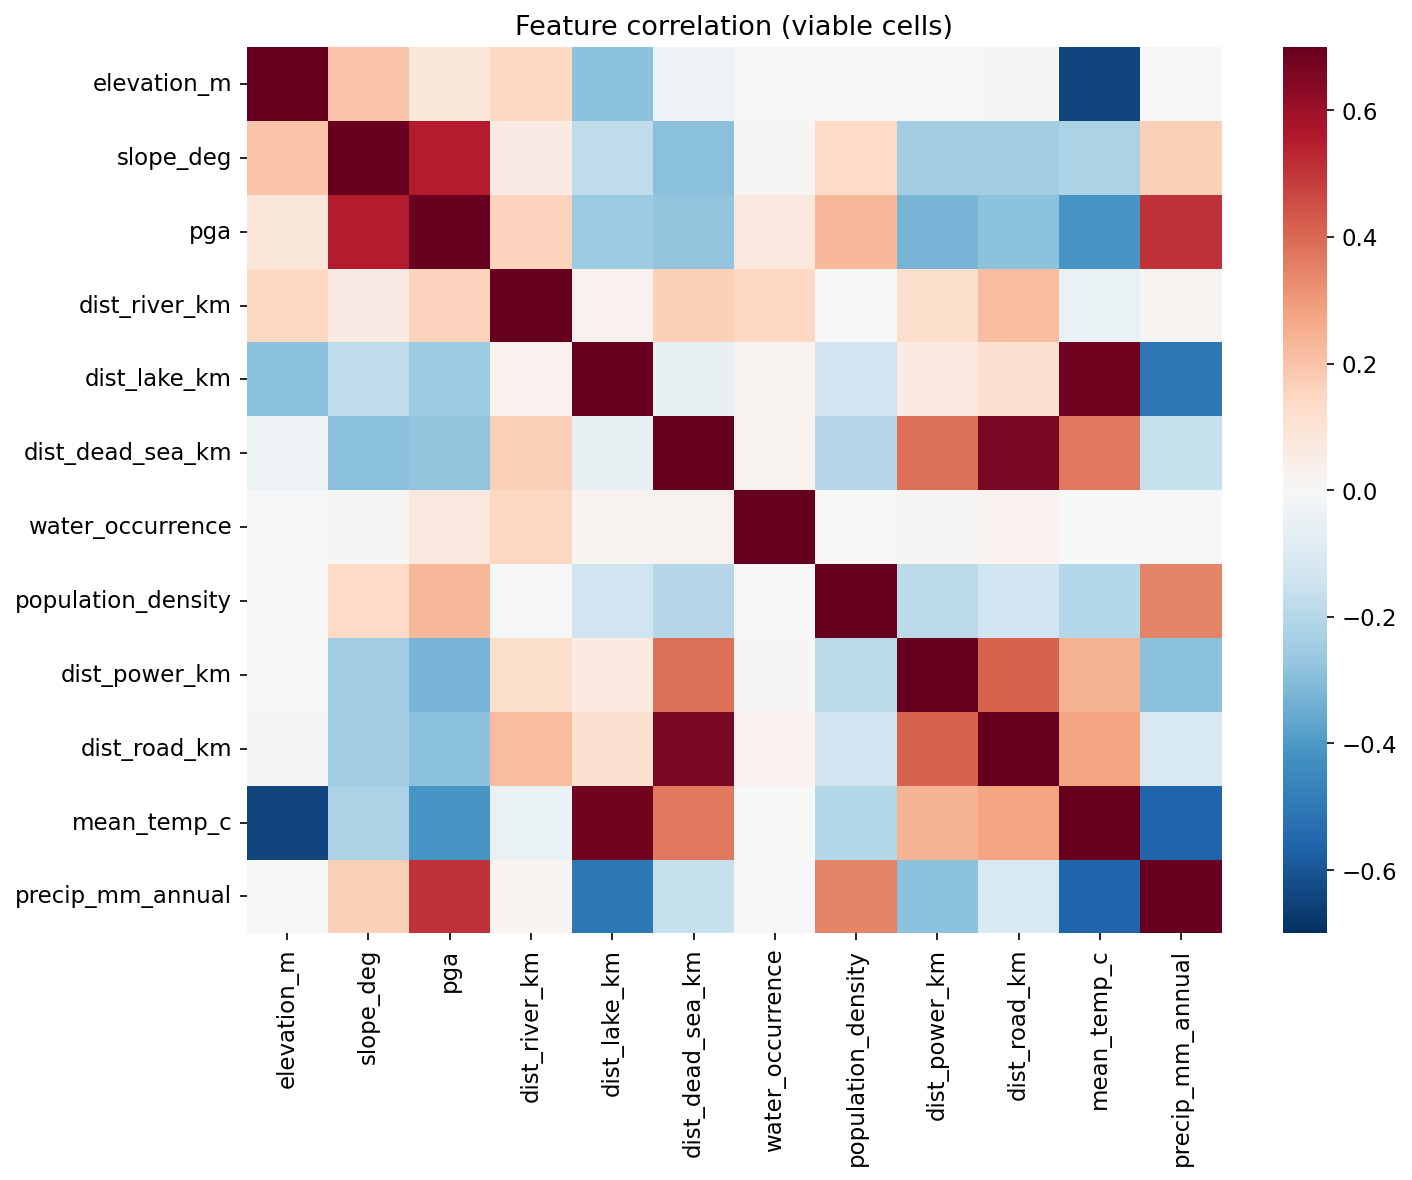

In [5]:
# Correlation heatmap
corr = df_viable[available].corr()
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, annot=False, cmap='RdBu_r', center=0, vmin=-0.7, vmax=0.7, ax=ax)
ax.set_title('Feature correlation (viable cells)')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'eda_correlation_heatmap.png', dpi=120, bbox_inches='tight')
plt.show()
plt.close(fig)

Loading feature CSV …
  151,156 cells loaded
  Grid shape: (622, 529)   elev range: -415–1753 m


/var/folders/nm/1ll2zl4s3bl526164b70tp0h0000gn/T/ipykernel_10017/422944394.py:122: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


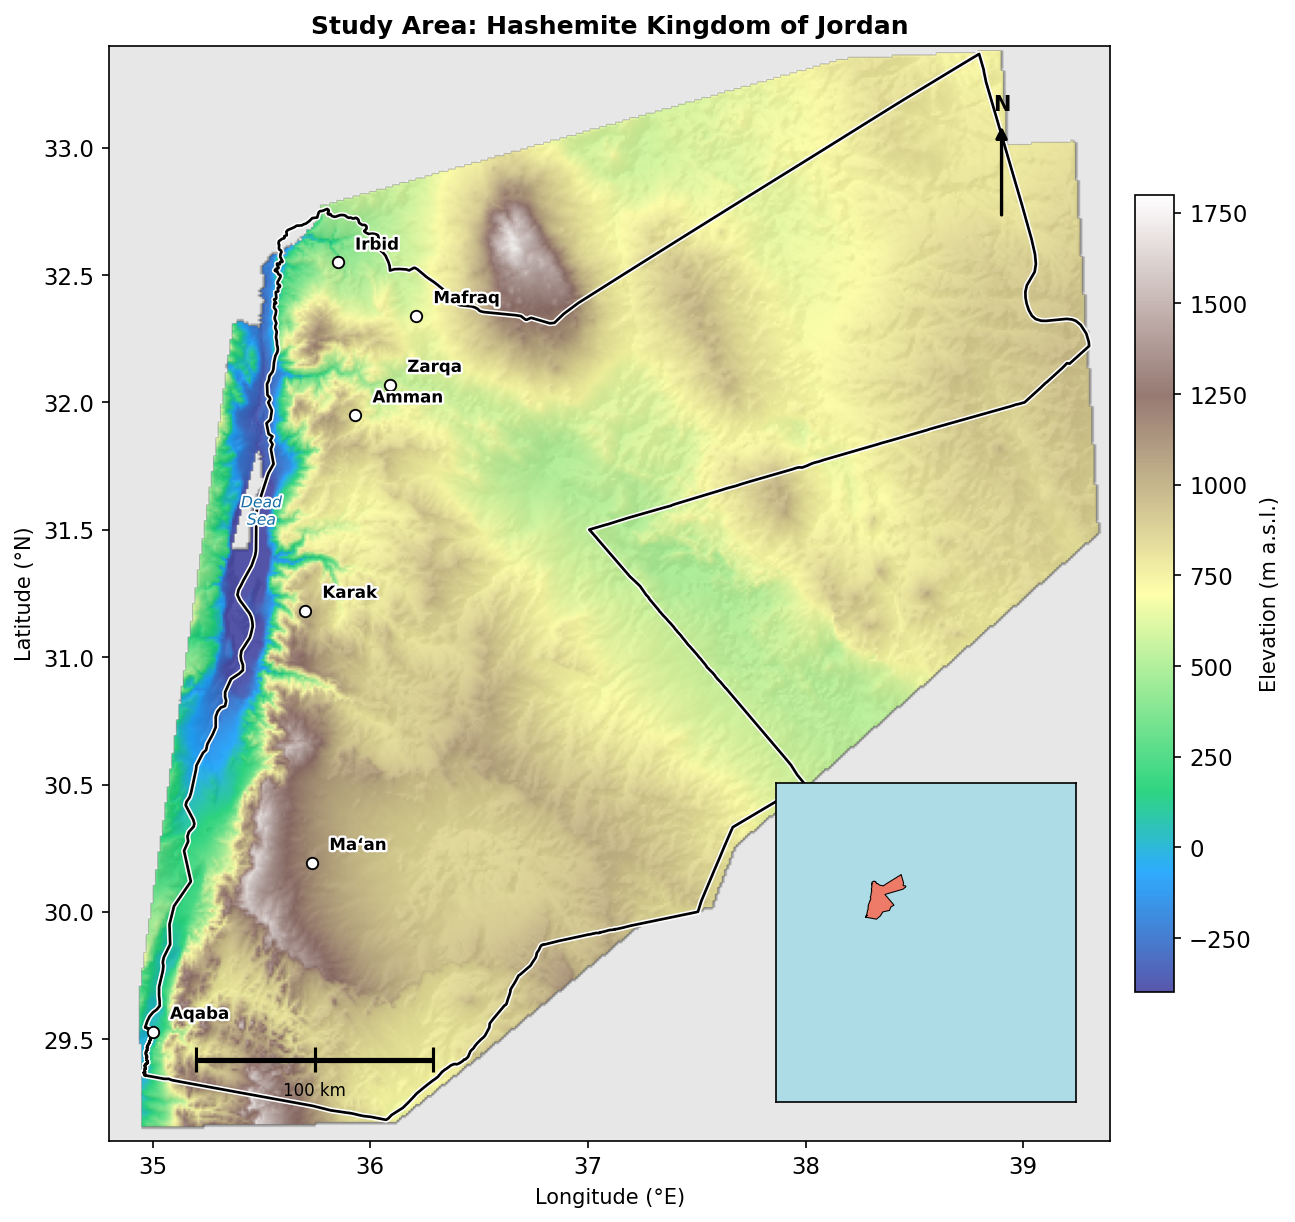

Saved → /Users/rajinasrallah/Desktop/databases/output/final/fig1_study_area.png


In [6]:
# Figure 1 — Study area map  (fast: grids elevation from the feature CSV, no raster merge)
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.patheffects as pe
from matplotlib.colors import LightSource

_root        = Path.cwd()
CSV_PATH     = _root / "output" / "final" / "jordan_smr_features_final.csv"
FIG_PATH     = _root / "output" / "final" / "fig1_study_area.png"

# ── 1. Load feature table ────────────────────────────────────────────────
print("Loading feature CSV …")
df = pd.read_csv(CSV_PATH, usecols=["row", "col", "lon", "lat", "elevation_m"])
print(f"  {len(df):,} cells loaded")

# ── 2. Build 2-D elevation grid using row / col indices ──────────────────
r0, c0   = int(df["row"].min()), int(df["col"].min())
n_rows   = int(df["row"].max()) - r0 + 1
n_cols   = int(df["col"].max()) - c0 + 1

grid = np.full((n_rows, n_cols), np.nan, dtype=np.float32)
ri   = (df["row"].to_numpy(dtype=int) - r0)
ci   = (df["col"].to_numpy(dtype=int) - c0)
grid[ri, ci] = df["elevation_m"].to_numpy(dtype=np.float32)
print(f"  Grid shape: {grid.shape}   elev range: {np.nanmin(grid):.0f}–{np.nanmax(grid):.0f} m")

# Geographic extent from the lon/lat columns
west  = df["lon"].min();  east  = df["lon"].max()
south = df["lat"].min();  north = df["lat"].max()
extent = (west, east, south, north)   # for imshow

# ── 3. Hillshade ─────────────────────────────────────────────────────────
ls        = LightSource(azdeg=315, altdeg=35)
elev_fill = np.where(np.isnan(grid), 0.0, grid)
hs        = ls.hillshade(elev_fill, vert_exag=5, dx=1, dy=1)

# ── 4. Plot ───────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(9, 10))

ax.imshow(hs,   extent=extent, origin="upper",
          cmap="gray", vmin=0, vmax=1, alpha=0.40, zorder=1)
im = ax.imshow(grid, extent=extent, origin="upper",
               cmap="terrain", vmin=-400, vmax=1800, alpha=0.82, zorder=2)

cb = plt.colorbar(im, ax=ax, shrink=0.55, pad=0.02)
cb.set_label("Elevation (m a.s.l.)", fontsize=10)

# Jordan border outline (official GADM boundary)
jordan_wgs84.boundary.plot(
    ax=ax,
    color="black",
    linewidth=1.3,
    zorder=5,
    path_effects=[pe.Stroke(linewidth=2.8, foreground="white"), pe.Normal()],
)

# Cities
cities = {
    "Amman":  (35.930, 31.950),
    "Zarqa":  (36.090, 32.070),
    "Irbid":  (35.850, 32.550),
    "Aqaba":  (35.000, 29.530),
    "Mafraq": (36.210, 32.340),
    "Karak":  (35.700, 31.183),
    "Ma\u02bban": (35.732, 30.193),
}
for city, (lon, lat) in cities.items():
    ax.scatter(lon, lat, s=30, c="white", edgecolors="black",
               linewidths=0.9, zorder=8)
    ax.text(lon + 0.08, lat + 0.05, city, fontsize=8, fontweight="bold",
            zorder=9,
            path_effects=[pe.Stroke(linewidth=2.2, foreground="white"), pe.Normal()])

# Dead Sea label
ax.text(35.50, 31.52, "Dead\nSea", fontsize=7.5, color="#1a6fa8",
        ha="center", style="italic", zorder=9,
        path_effects=[pe.Stroke(linewidth=2, foreground="white"), pe.Normal()])

# North arrow
ax.annotate("", xy=(38.9, 33.10), xytext=(38.9, 32.72),
            arrowprops=dict(arrowstyle="-|>", color="black", lw=1.6), zorder=10)
ax.text(38.9, 33.13, "N", ha="center", va="bottom",
        fontsize=10, fontweight="bold", zorder=10)

# Scale bar  (~100 km; 1° lon ≈ 92 km at 31°N)
s0, s1, slat = 35.2, 36.29, 29.42
ax.hlines(slat, s0, s1, colors="black", linewidths=2.5, zorder=10)
for t in [s0, (s0+s1)/2, s1]:
    ax.vlines(t, slat-0.05, slat+0.05, colors="black", linewidths=1.5, zorder=10)
ax.text((s0+s1)/2, slat-0.14, "100 km", ha="center", fontsize=8, zorder=10)

# Regional inset (bottom-right, inside main axes)
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

ax_in = inset_axes(
    ax,
    width="30%",
    height="30%",
    loc="lower right",
    borderpad=1.5,
)

ax_in.set_facecolor("#ADDBE6")
ax_in.set_xlim(25, 58)
ax_in.set_ylim(12, 42)
ax_in.set_xticks([])
ax_in.set_yticks([])

# Draw Jordan outline on inset
jordan_wgs84.plot(ax=ax_in, color="tomato", alpha=0.8)
jordan_wgs84.boundary.plot(ax=ax_in, color="black", linewidth=0.5)

ax.set_xlim(34.8, 39.4)
ax.set_ylim(29.1, 33.4)
ax.set_xlabel("Longitude (°E)", fontsize=10)
ax.set_ylabel("Latitude (°N)",  fontsize=10)
ax.set_title("Study Area: Hashemite Kingdom of Jordan", fontsize=12, fontweight="bold")

plt.tight_layout()
plt.savefig(FIG_PATH, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)
print(f"Saved → {FIG_PATH}")

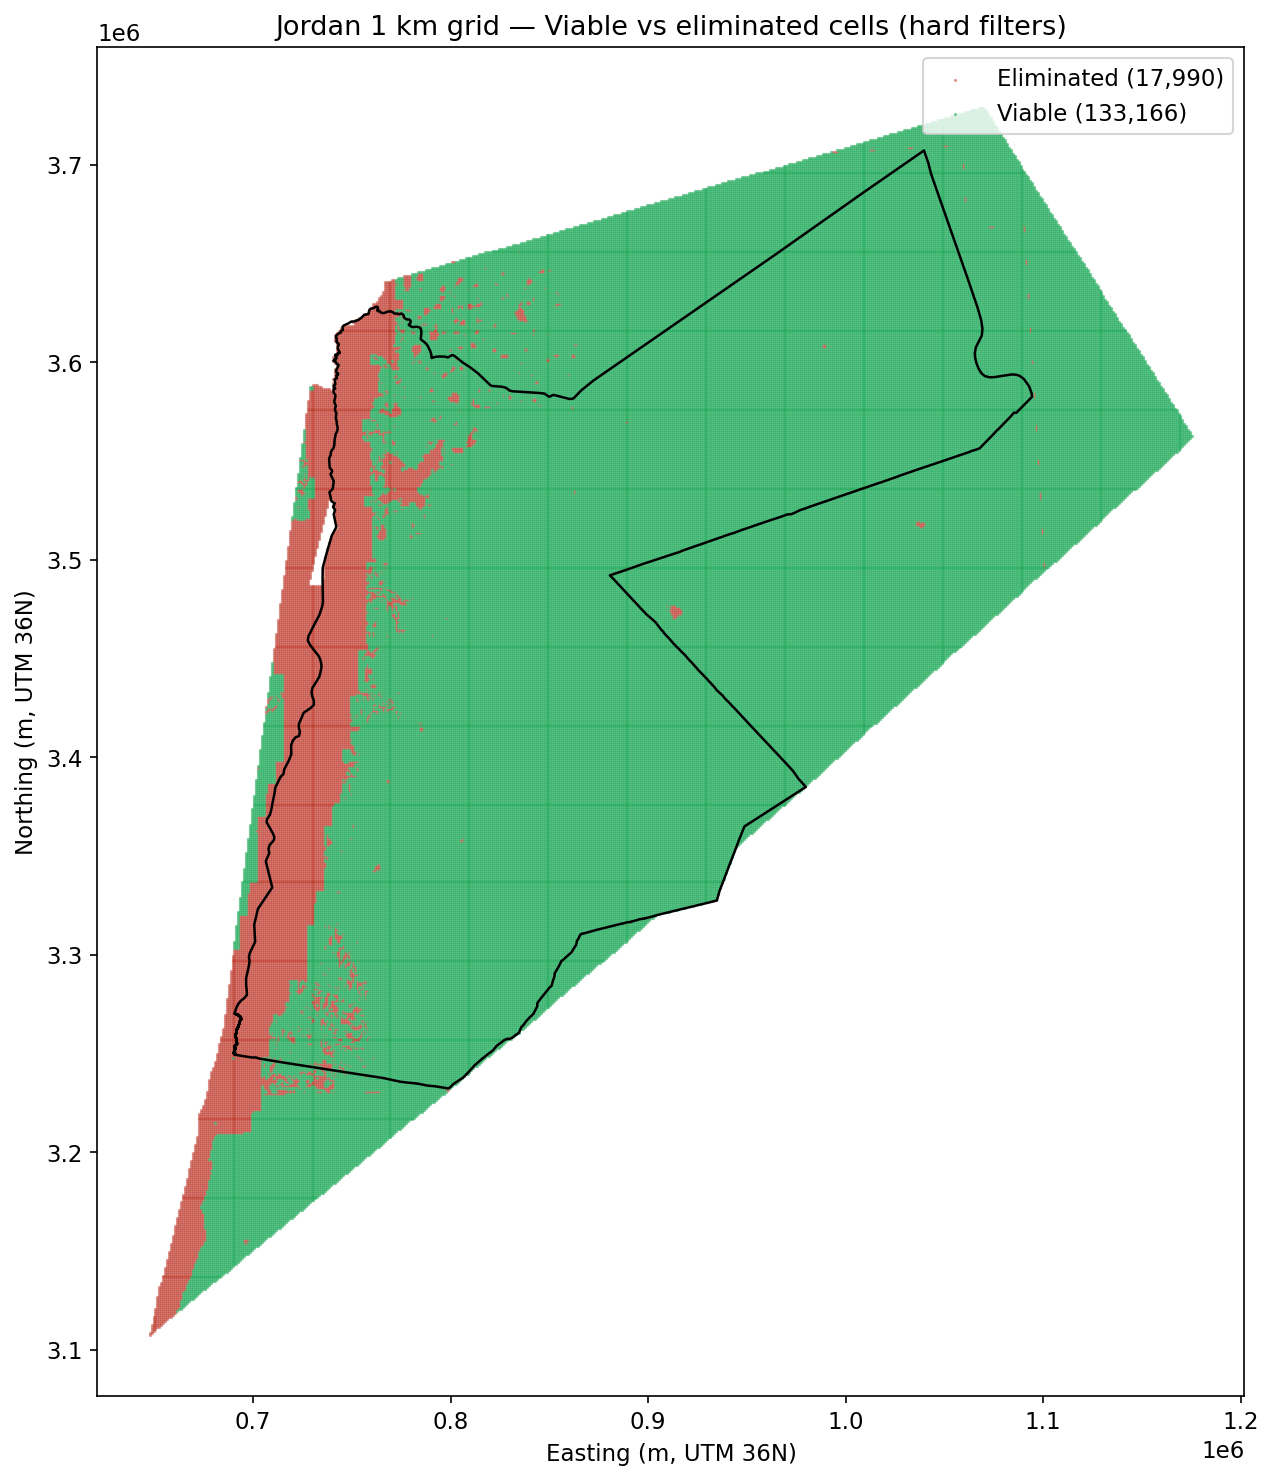

In [8]:
# Map: viable vs eliminated cells (UTM)

# Use a local dataframe so this cell can't be broken by a different global `df`
required_cols = {
    'x_utm', 'y_utm',
    'pga', 'population_density', 'slope_deg', 'water_occurrence'
}

if 'df' in globals() and required_cols.issubset(set(df.columns)):
    df_map = df
else:
    features_csv = (features_path if 'features_path' in globals() else (OUTPUT_DIR / 'jordan_smr_features.csv'))
    df_map = pd.read_csv(features_csv)

# Ensure a viable flag exists (hard filters)
if 'viable' not in df_map.columns:
    df_map = df_map.copy()
    df_map['viable'] = (
        (df_map['pga'] <= PGA_LIMIT) &
        (df_map['population_density'] <= POP_LIMIT) &
        (df_map['slope_deg'] <= SLOPE_LIMIT) &
        (df_map['water_occurrence'] <= WATER_OCC_LIMIT)
    ).astype(int)

fig, ax = plt.subplots(figsize=(10, 10))
elim = df_map[df_map['viable'] == 0]
via = df_map[df_map['viable'] == 1]
if len(elim) > 0:
    ax.scatter(elim['x_utm'], elim['y_utm'], c='#c0392b', s=0.3, alpha=0.5, label=f'Eliminated ({len(elim):,})', rasterized=True)
if len(via) > 0:
    ax.scatter(via['x_utm'], via['y_utm'], c='#27ae60', s=0.3, alpha=0.6, label=f'Viable ({len(via):,})', rasterized=True)

# Jordan boundary (UTM)
jordan_utm.boundary.plot(ax=ax, color='black', linewidth=1.2, zorder=4)

ax.set_xlabel('Easting (m, UTM 36N)')
ax.set_ylabel('Northing (m, UTM 36N)')
ax.set_title('Jordan 1 km grid — Viable vs eliminated cells (hard filters)')
ax.legend(loc='upper right')
ax.set_aspect('equal')
plt.tight_layout()

# Paper figure (300 DPI) + keep original EDA filename for backwards-compatibility
plt.savefig(OUTPUT_DIR / 'fig2_viable_eliminated.png', dpi=300, bbox_inches='tight')
plt.savefig(OUTPUT_DIR / 'eda_viable_eliminated_map.png', dpi=300, bbox_inches='tight')
plt.show()
plt.close(fig)

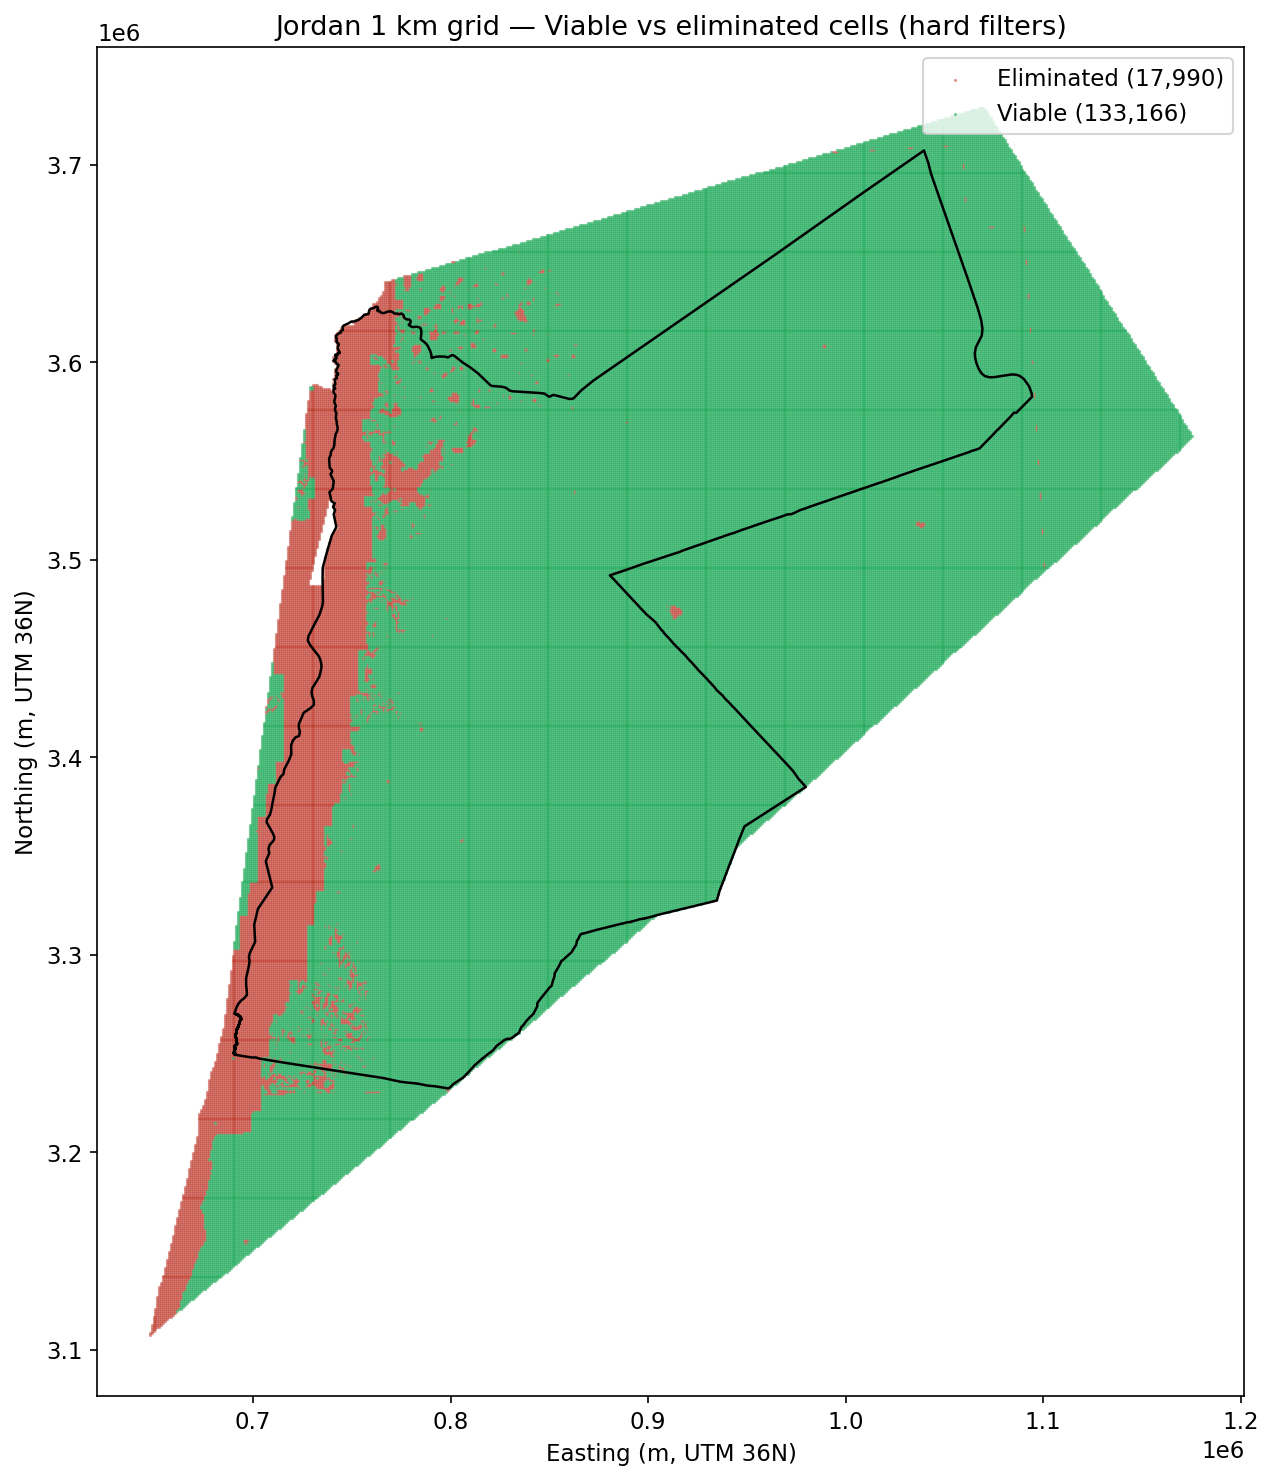

In [9]:
# Map: viable vs eliminated cells (UTM)

# Use a local dataframe so this cell can't be broken by a different global `df`
required_cols = {
    'x_utm', 'y_utm',
    'pga', 'population_density', 'slope_deg', 'water_occurrence'
}

if 'df' in globals() and required_cols.issubset(set(df.columns)):
    df_map = df
else:
    features_csv = (features_path if 'features_path' in globals() else (OUTPUT_DIR / 'jordan_smr_features.csv'))
    df_map = pd.read_csv(features_csv)

# Ensure a viable flag exists (hard filters)
if 'viable' not in df_map.columns:
    df_map = df_map.copy()
    df_map['viable'] = (
        (df_map['pga'] <= PGA_LIMIT) &
        (df_map['population_density'] <= POP_LIMIT) &
        (df_map['slope_deg'] <= SLOPE_LIMIT) &
        (df_map['water_occurrence'] <= WATER_OCC_LIMIT)
    ).astype(int)

fig, ax = plt.subplots(figsize=(10, 10))
elim = df_map[df_map['viable'] == 0]
via = df_map[df_map['viable'] == 1]
if len(elim) > 0:
    ax.scatter(elim['x_utm'], elim['y_utm'], c='#c0392b', s=0.3, alpha=0.5, label=f'Eliminated ({len(elim):,})', rasterized=True)
if len(via) > 0:
    ax.scatter(via['x_utm'], via['y_utm'], c='#27ae60', s=0.3, alpha=0.6, label=f'Viable ({len(via):,})', rasterized=True)

# Jordan boundary (UTM)
jordan_utm.boundary.plot(ax=ax, color='black', linewidth=1.2, zorder=4)

ax.set_xlabel('Easting (m, UTM 36N)')
ax.set_ylabel('Northing (m, UTM 36N)')
ax.set_title('Jordan 1 km grid — Viable vs eliminated cells (hard filters)')
ax.legend(loc='upper right')
ax.set_aspect('equal')
plt.tight_layout()

# Paper figure (300 DPI) + keep original EDA filename for backwards-compatibility
plt.savefig(OUTPUT_DIR / 'fig2_viable_eliminated.png', dpi=300, bbox_inches='tight')
plt.savefig(OUTPUT_DIR / 'eda_viable_eliminated_map.png', dpi=300, bbox_inches='tight')
plt.show()

In [10]:
# Summary statistics table
summary = df_viable[available].describe().T[['mean', 'std', 'min', 'max']].round(4)
summary['count'] = df_viable[available].count()
summary = summary[['count', 'mean', 'std', 'min', 'max']]
print('Summary statistics (viable cells):')
summary

Summary statistics (viable cells):


,count,mean,std,min,max
elevation_m,117328,793.9562,184.7678,-177.4728,1753.4370
slope_deg,117328,2.8919,2.3751,0.4684,17.9956
pga,133164,0.0845,0.0567,0.0220,0.3000
dist_river_km,133166,1.5534,2.2006,0.0024,52.7647
dist_lake_km,133166,69.4477,47.0576,0.0097,202.3513
dist_dead_sea_km,133166,211.1881,93.2809,10.7546,432.5116
water_occurrence,133166,0.0272,1.2023,0.0000,79.0496
population_density,133166,10.8907,66.9275,0.0000,999.5786
dist_power_km,133166,53.2505,27.1502,0.1087,125.8691
dist_road_km,133166,40.3326,33.6247,0.0015,152.5646


---
## Section 3 — Label Generation (IAEA SSG-35 Based)

**IAEA Safety Standards SSG-35** (siting of nuclear installations) and related guidance recommend:
- Low seismic hazard (e.g. PGA below a threshold).
- Low population density and avoidance of dense urban areas.
- Stable terrain (moderate slope).
- Access to cooling water (proximity to rivers) while avoiding siting on permanent water bodies.
- Reasonable access to infrastructure (roads, grid).

We define **binary labels** for Stage 1:
- **Positive (highly suitable):** pga &lt; 0.15*g*, slope &lt; 5°, population &lt; 100/km², dist_river &lt; 10 km, water_occurrence &lt; 20, dist_road &lt; 50 km (all criteria met).
- **Negative:** Passed hard filters but does not meet all positive criteria.

Only **viable** cells (that passed the hard filters) are used for labeling and training.

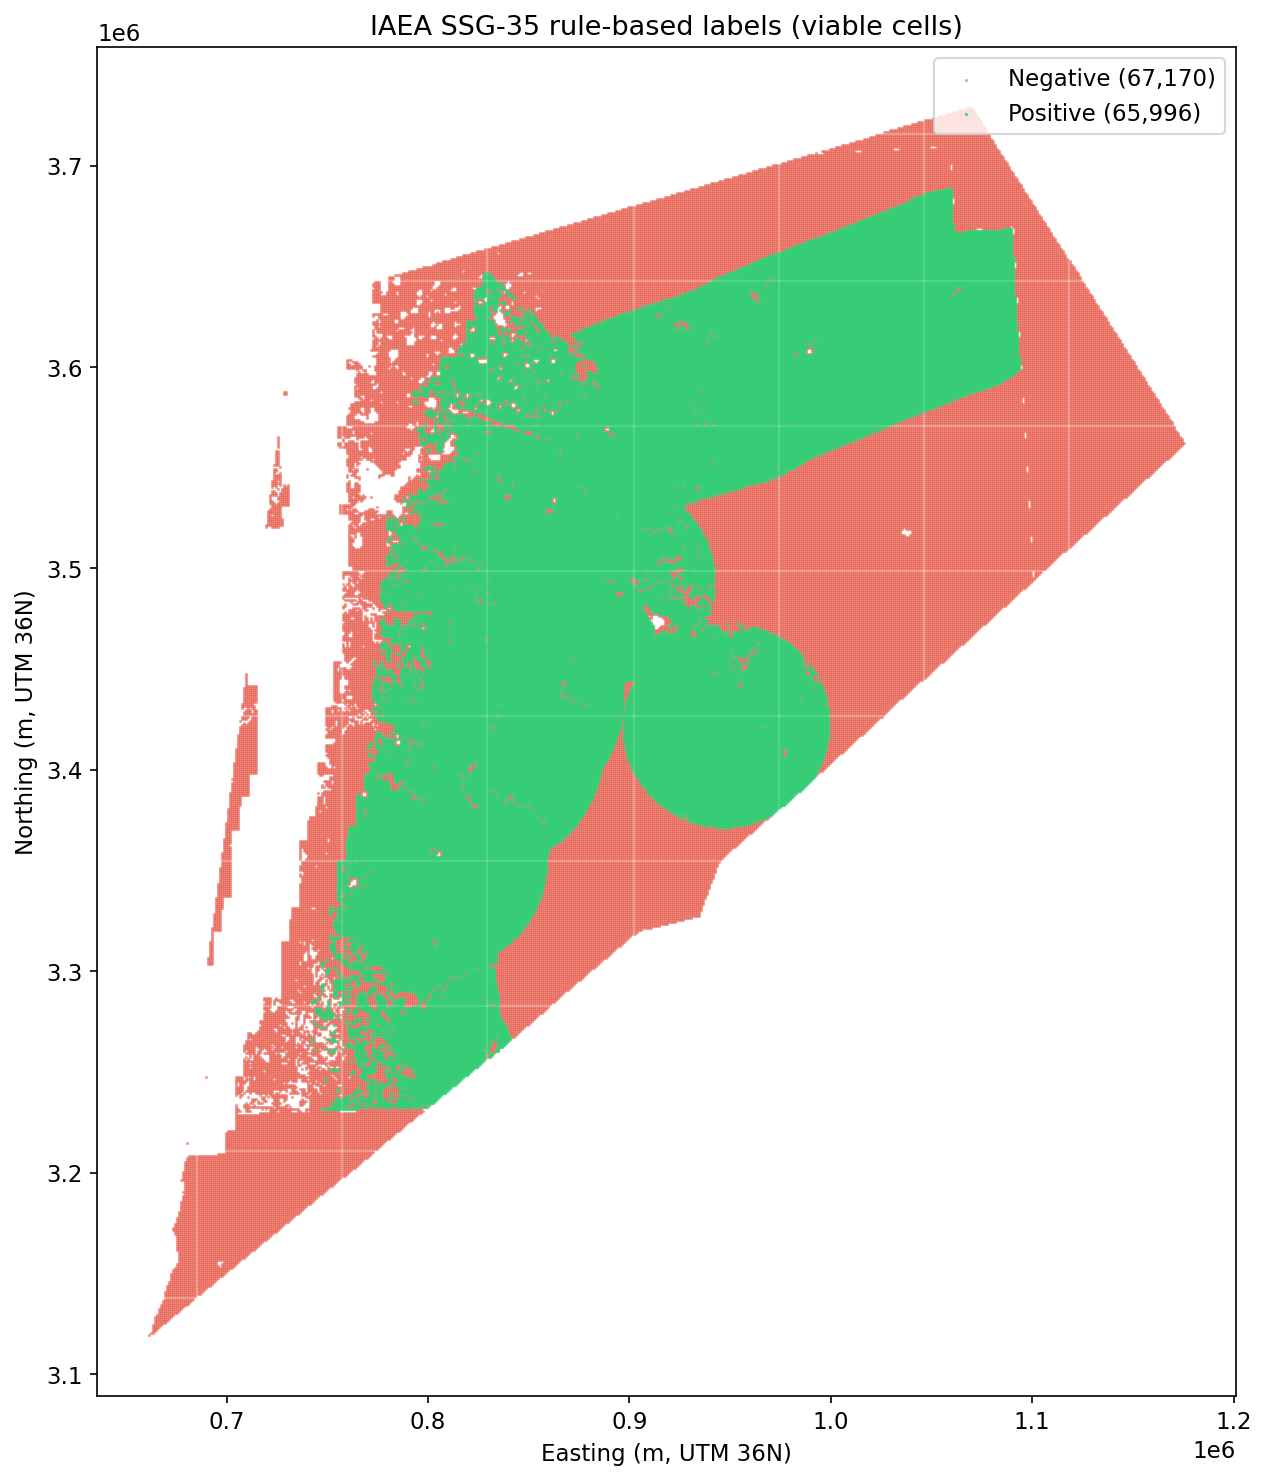

In [12]:
# Map: positive vs negative cells

# Ensure df_ml is available (so this cell can run independently)
if 'df_ml' not in globals():
    features_final_csv = (features_final_path if 'features_final_path' in globals() else (OUTPUT_DIR / 'jordan_smr_features_final.csv'))
    df_ml = pd.read_csv(features_final_csv)

fig, ax = plt.subplots(figsize=(10, 10))
neg = df_ml[df_ml['label_positive'] == 0]
pos = df_ml[df_ml['label_positive'] == 1]
if len(neg) > 0:
    ax.scatter(neg['x_utm'], neg['y_utm'], c='#e74c3c', s=0.3, alpha=0.5, label=f'Negative ({len(neg):,})', rasterized=True)
if len(pos) > 0:
    ax.scatter(pos['x_utm'], pos['y_utm'], c='#2ecc71', s=0.5, alpha=0.7, label=f'Positive ({len(pos):,})', rasterized=True)
ax.set_xlabel('Easting (m, UTM 36N)')
ax.set_ylabel('Northing (m, UTM 36N)')
ax.set_title('IAEA SSG-35 rule-based labels (viable cells)')
ax.legend(loc='upper right')
ax.set_aspect('equal')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'labels_positive_negative_map.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close(fig)

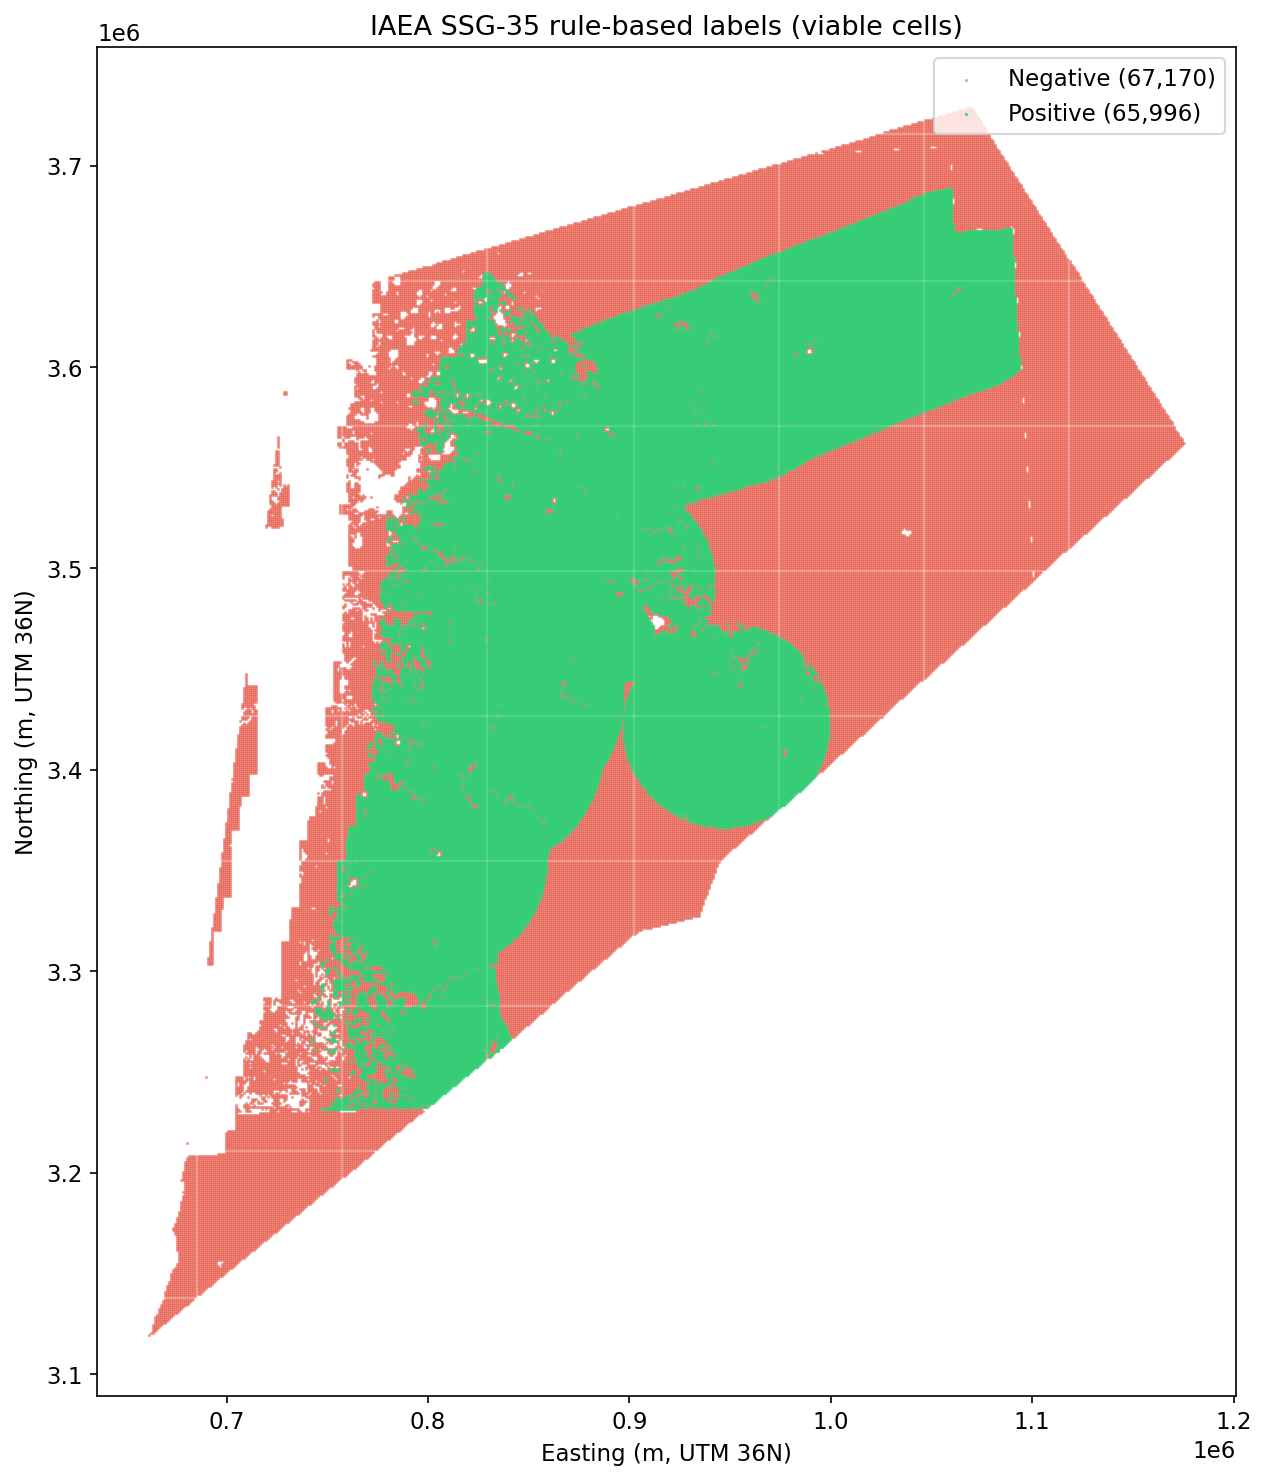

In [13]:
# Map: positive vs negative cells

# Ensure df_ml is available (so this cell can run independently)
if 'df_ml' not in globals():
    features_final_csv = (features_final_path if 'features_final_path' in globals() else (OUTPUT_DIR / 'jordan_smr_features_final.csv'))
    df_ml = pd.read_csv(features_final_csv)

fig, ax = plt.subplots(figsize=(10, 10))
neg = df_ml[df_ml['label_positive'] == 0]
pos = df_ml[df_ml['label_positive'] == 1]
if len(neg) > 0:
    ax.scatter(neg['x_utm'], neg['y_utm'], c='#e74c3c', s=0.3, alpha=0.5, label=f'Negative ({len(neg):,})', rasterized=True)
if len(pos) > 0:
    ax.scatter(pos['x_utm'], pos['y_utm'], c='#2ecc71', s=0.5, alpha=0.7, label=f'Positive ({len(pos):,})', rasterized=True)
ax.set_xlabel('Easting (m, UTM 36N)')
ax.set_ylabel('Northing (m, UTM 36N)')
ax.set_title('IAEA SSG-35 rule-based labels (viable cells)')
ax.legend(loc='upper right')
ax.set_aspect('equal')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'labels_positive_negative_map.png', dpi=150, bbox_inches='tight')
plt.show()

# Prepare X, y — drop rows with missing labels or too many missing features
use_cols = [c for c in FEATURE_COLS if c in df_ml.columns]
X_full = df_ml[use_cols].copy()
y_full = df_ml['label_positive']
# Impute missing with median for LR
for c in use_cols:
    X_full[c] = X_full[c].fillna(X_full[c].median())

X_train, X_test, y_train, y_test = train_test_split(
    X_full, y_full, test_size=0.2, random_state=RANDOM_STATE, stratify=y_full
)

lr = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
lr.fit(X_train, y_train)
y_pred = lr.predict(X_test)
y_prob = lr.predict_proba(X_test)[:, 1]

print('Stage 1 — Logistic Regression')
print('  Accuracy:  ', round(accuracy_score(y_test, y_pred), 4))
print('  Precision: ', round(precision_score(y_test, y_pred, zero_division=0), 4))
print('  Recall:    ', round(recall_score(y_test, y_pred, zero_division=0), 4))
print('  F1:        ', round(f1_score(y_test, y_pred, zero_division=0), 4))
print('  AUC-ROC:   ', round(roc_auc_score(y_test, y_prob), 4))
print('\nConfusion matrix:')
print(confusion_matrix(y_test, y_pred))

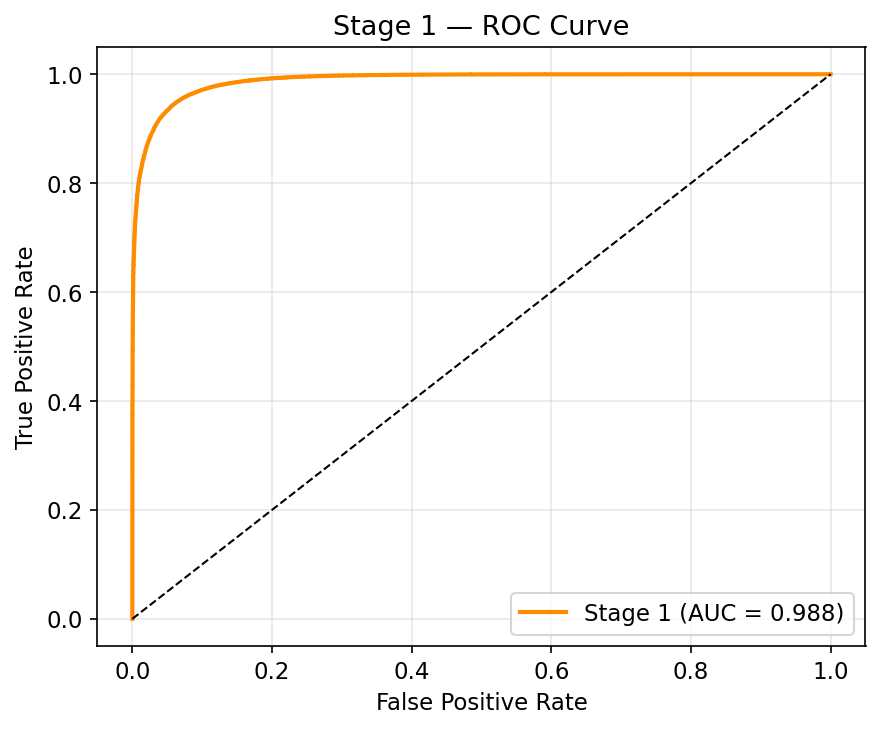

In [20]:
# ROC curve (Stage 1)

# This cell is restart-safe: it recomputes ROC from saved outputs.
features_final_csv = (features_final_path if 'features_final_path' in globals() else (OUTPUT_DIR / 'jordan_smr_features_final.csv'))
df_roc = pd.read_csv(features_final_csv)

# Use viable cells only (consistent with the pipeline)
df_roc = df_roc[df_roc['viable'] == 1].copy()
df_roc = df_roc[df_roc['label_positive'].notna() & df_roc['stage1_prob'].notna()].copy()

y_true = df_roc['label_positive'].astype(int)
y_score = df_roc['stage1_prob'].astype(float)

fpr, tpr, _ = roc_curve(y_true, y_score)
auc = roc_auc_score(y_true, y_score)

fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(fpr, tpr, color='darkorange', lw=2, label=f'Stage 1 (AUC = {auc:.3f})')
ax.plot([0, 1], [0, 1], 'k--', lw=1)
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('Stage 1 — ROC Curve')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'stage1_roc_curve.png', dpi=300, bbox_inches='tight')
plt.show()
plt.close(fig)

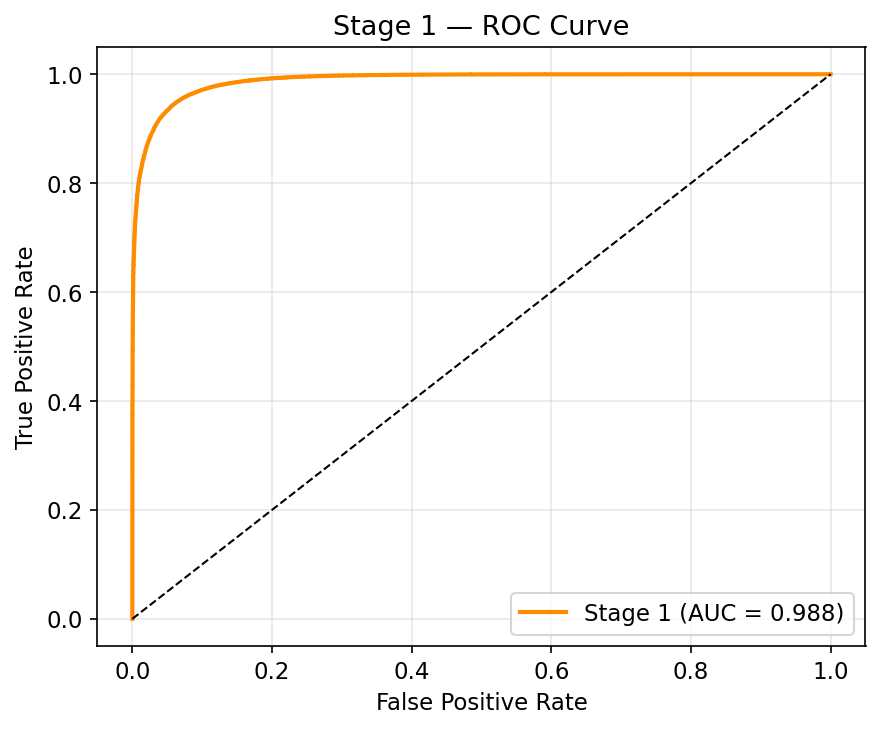

In [21]:
# ROC curve (Stage 1)

# This cell is restart-safe: it recomputes ROC from saved outputs.
features_final_csv = (features_final_path if 'features_final_path' in globals() else (OUTPUT_DIR / 'jordan_smr_features_final.csv'))
df_roc = pd.read_csv(features_final_csv)

# Use viable cells only (consistent with the pipeline)
df_roc = df_roc[df_roc['viable'] == 1].copy()
df_roc = df_roc[df_roc['label_positive'].notna() & df_roc['stage1_prob'].notna()].copy()

y_true = df_roc['label_positive'].astype(int)
y_score = df_roc['stage1_prob'].astype(float)

fpr, tpr, _ = roc_curve(y_true, y_score)
auc = roc_auc_score(y_true, y_score)

fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(fpr, tpr, color='darkorange', lw=2, label=f'Stage 1 (AUC = {auc:.3f})')
ax.plot([0, 1], [0, 1], 'k--', lw=1)
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('Stage 1 — ROC Curve')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'stage1_roc_curve.png', dpi=300, bbox_inches='tight')
plt.show()

In [27]:
# Predict on full viable set and attach to df_ml (restart-safe)

# Prefer loading precomputed outputs if available
features_final_csv = (features_final_path if 'features_final_path' in globals() else (OUTPUT_DIR / 'jordan_smr_features_final.csv'))
if ('df_ml' not in globals()) or (not {'stage1_label', 'stage1_prob'}.issubset(set(getattr(df_ml, 'columns', [])))):
    try:
        df_ml = pd.read_csv(features_final_csv)
    except FileNotFoundError:
        # Fall back to whatever df_ml exists; later logic will handle missing pieces
        pass

# If predictions already exist, just report and move on
if 'df_ml' in globals() and {'stage1_label', 'stage1_prob'}.issubset(set(df_ml.columns)):
    print('Stage1 predictions already present. Value counts:')
    print(df_ml['stage1_label'].value_counts())
else:
    # Otherwise, we can only predict if an LR model and feature list are available
    if 'df_ml' not in globals():
        raise NameError("df_ml is not defined and could not be loaded.")

    if 'use_cols' not in globals():
        # Infer candidate feature columns (exclude ids/coords/targets)
        exclude = {
            'cell_id','row','col','x_utm','y_utm','lon','lat',
            'viable','stage1_label','stage1_prob','suitability_score','suitability_target','label_positive'
        }
        use_cols = [c for c in df_ml.columns if c not in exclude]

    if 'lr' not in globals():
        raise NameError("Stage 1 model `lr` is not defined. Run the Stage 1 training cell first, or use the precomputed CSV outputs.")

    X_imputed = df_ml[use_cols].copy()
    for c in use_cols:
        X_imputed[c] = X_imputed[c].fillna(X_imputed[c].median())

    df_ml['stage1_label'] = lr.predict(X_imputed)
    df_ml['stage1_prob'] = lr.predict_proba(X_imputed)[:, 1]

    print('Stage1 predictions attached. Value counts:')
    print(df_ml['stage1_label'].value_counts())

Stage1 predictions already present. Value counts:
stage1_label
0.0    66637
1.0    66529
Name: count, dtype: int64


---
## Section 5 — Stage 2: XGBoost Suitability Scoring

We build a **continuous suitability score (0–1)** using weighted feature contributions aligned with the water–energy nexus:
- **Water features (2× weight):** dist_river_km, dist_dead_sea_km, dist_lake_km, water_occurrence, precip_mm_annual.
- **Safety (1.5× weight):** pga, slope_deg.
- **Infrastructure (1× weight):** dist_road_km, dist_power_km, population_density.

We first construct a **target** from these weighted components (normalized to 0–1), then train an **XGBoost regressor** to predict it; the model's predictions serve as the final suitability score.

In [28]:
print('Composite suitability score summary (see previous cell).')
print(df_ml['suitability_score'].describe())


Composite suitability score summary (see previous cell).
count    133166.000000
mean          0.749093
std           0.101821
min           0.000000
25%           0.694936
50%           0.755070
75%           0.813202
max           1.000000
Name: suitability_score, dtype: float64


---
## Section 6 — SHAP Explainability

We compute **SHAP values** for the XGBoost model to interpret feature importance and direction of impact. The bar chart and beeswarm summary support the discussion of drivers of suitability in the paper.

Training XGBoost classifier on label_positive for SHAP analysis...
Top 5 most important features:
dist_dead_sea_km      0.695396
population_density    0.708832
pga                   1.784301
slope_deg             2.588886
dist_road_km          5.783763


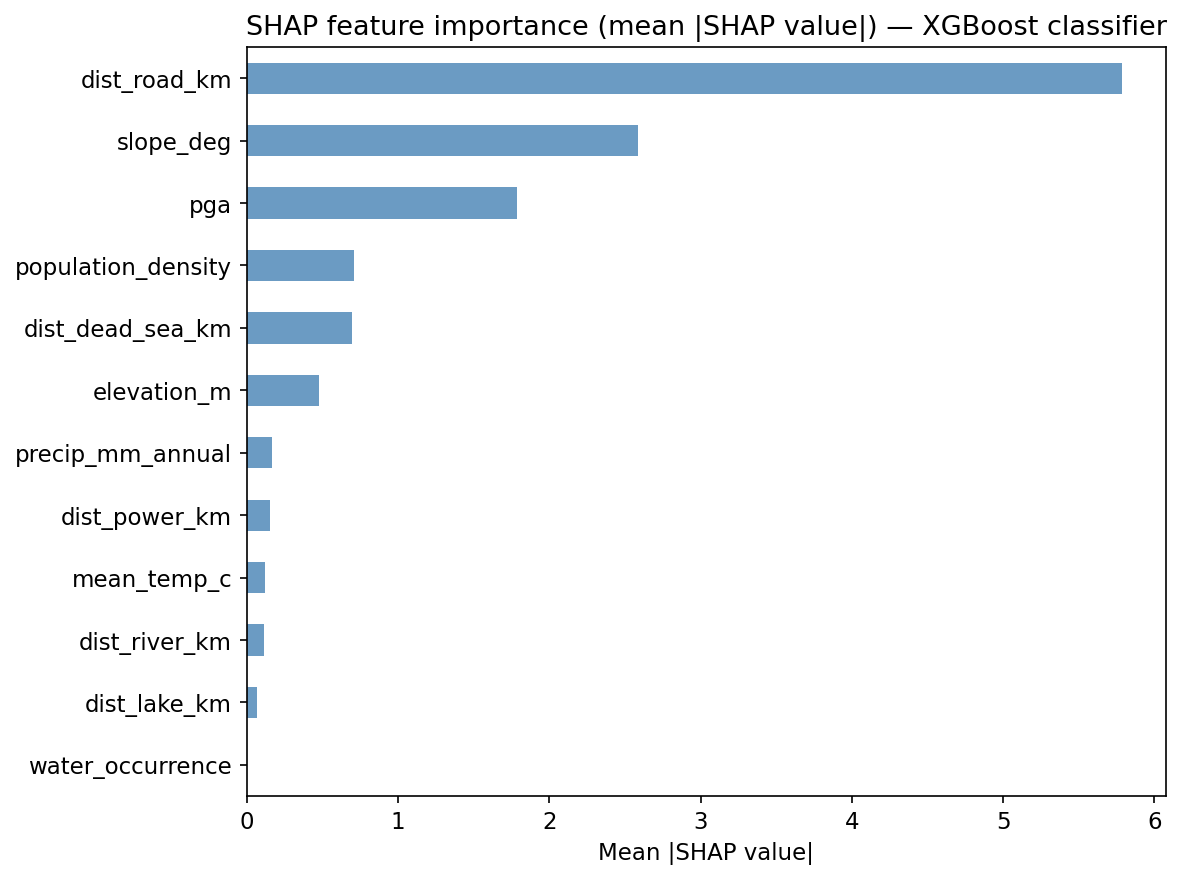

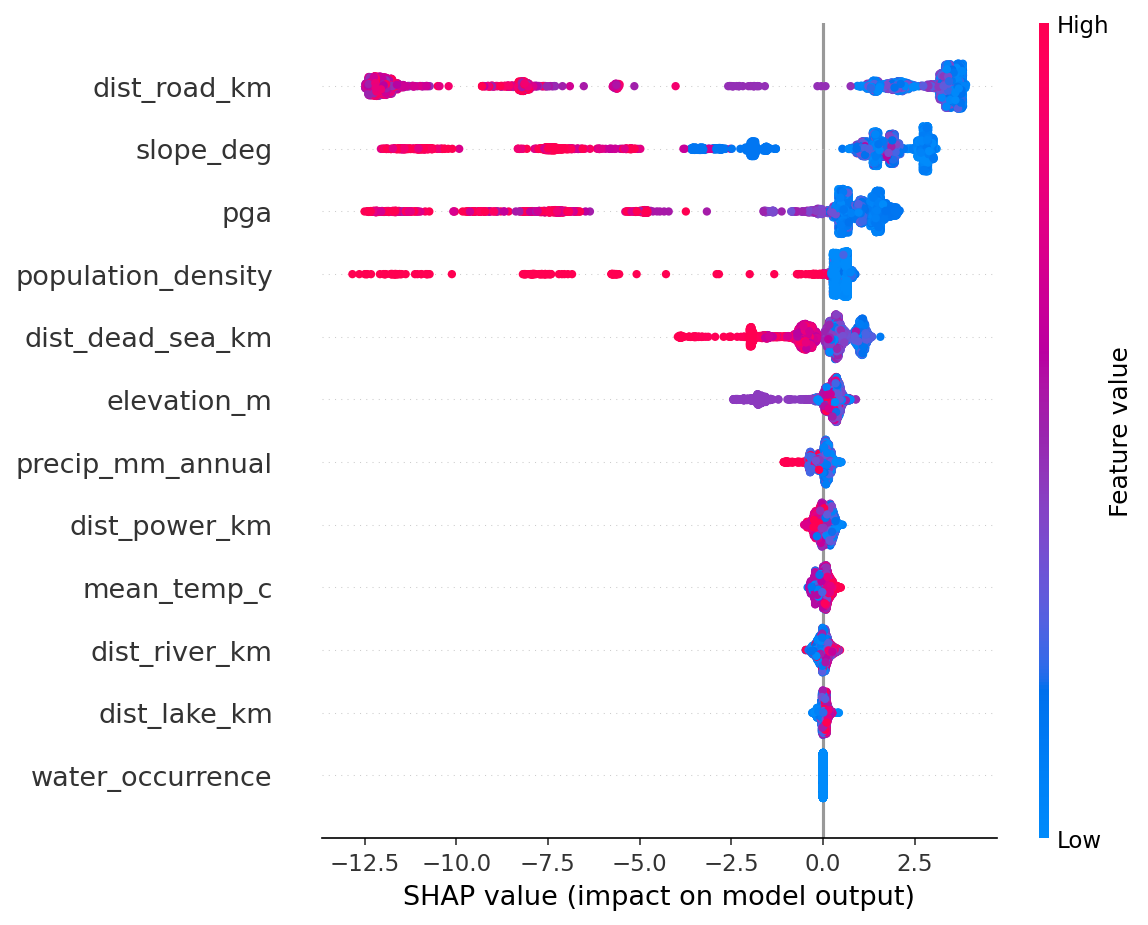

In [30]:
# SHAP explainability — XGBoost classifier on label_positive
print("Training XGBoost classifier on label_positive for SHAP analysis...")

# Restart-safe: ensure df_ml + use_cols exist
if 'df_ml' not in globals():
    features_final_csv = (features_final_path if 'features_final_path' in globals() else (OUTPUT_DIR / 'jordan_smr_features_final.csv'))
    df_ml = pd.read_csv(features_final_csv)

if 'use_cols' not in globals():
    exclude = {
        'cell_id','row','col','x_utm','y_utm','lon','lat',
        'viable','stage1_label','stage1_prob','suitability_score','suitability_target','label_positive'
    }
    use_cols = [c for c in df_ml.columns if c not in exclude]

X_shap_full = df_ml[use_cols].copy()
for c in use_cols:
    X_shap_full[c] = X_shap_full[c].fillna(X_shap_full[c].median())

y_shap_full = df_ml['label_positive']

# Drop rows with missing labels (restart-safe; some CSVs may have NaNs)
mask = y_shap_full.notna()
X_shap_full = X_shap_full.loc[mask]
y_shap_full = y_shap_full.loc[mask].astype(int)

# Downsample negatives if highly imbalanced
pos_idx = y_shap_full[y_shap_full == 1].index
neg_idx = y_shap_full[y_shap_full == 0].index
if len(pos_idx) > 0 and len(neg_idx) > 5 * len(pos_idx):
    neg_sample = neg_idx.to_series().sample(5 * len(pos_idx), random_state=RANDOM_STATE)
    idx_used = pos_idx.union(neg_sample)
    X_shap_full = X_shap_full.loc[idx_used]
    y_shap_full = y_shap_full.loc[idx_used]

xgb_clf = xgb.XGBClassifier(
    n_estimators=200,
    max_depth=4,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=RANDOM_STATE,
    n_jobs=4,
)
xgb_clf.fit(X_shap_full, y_shap_full)

sample_size = min(5000, len(X_shap_full))
X_shap = X_shap_full.sample(sample_size, random_state=RANDOM_STATE)

explainer = shap.TreeExplainer(xgb_clf)
shap_vals = explainer.shap_values(X_shap)

importance = pd.Series(np.abs(shap_vals).mean(axis=0), index=use_cols).sort_values()
print("Top 5 most important features:")
print(importance.tail(5).to_string())

# Bar chart
fig, ax = plt.subplots(figsize=(8, 6))
importance.plot(kind='barh', ax=ax, color='steelblue', alpha=0.8)
ax.set_title('SHAP feature importance (mean |SHAP value|) — XGBoost classifier')
ax.set_xlabel('Mean |SHAP value|')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'shap_importance_bar.png', dpi=120, bbox_inches='tight')
plt.show()
plt.close(fig)

# Beeswarm summary (SHAP creates its own figure internally)
shap.summary_plot(shap_vals, X_shap, show=False)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'shap_beeswarm.png', dpi=120, bbox_inches='tight')
plt.savefig(OUTPUT_DIR / 'shap_summary_beeswarm.png', dpi=120, bbox_inches='tight')
plt.show()
plt.close()

**Top 3 features (typical interpretation):**  
1. **dist_river_km** — Closer to rivers increases suitability (cooling water access).  
2. **pga** — Lower seismic hazard increases suitability (safety).  
3. **dist_road_km** or **population_density** — Better infrastructure access and lower population density favour siting.  

*(Interpret exact order from the SHAP bar chart and beeswarm in your run.)*

---
## Section 7 — Suitability Heatmap

We plot Jordan as a **heatmap** coloured by suitability score (red = high, blue = low). Only viable cells are included; eliminated cells can be shown in grey or omitted.

Suitability score distribution (viable cells):
  min : 0.0
  max : 1.0
  mean: 0.7490927658256038
  std : 0.10182092582346874
  p10 : 0.6412013541086048
  p90 : 0.8704186428782282
Using vmin = 0.5802017619553334 vmax = 0.9014471170206507 for colormap stretch


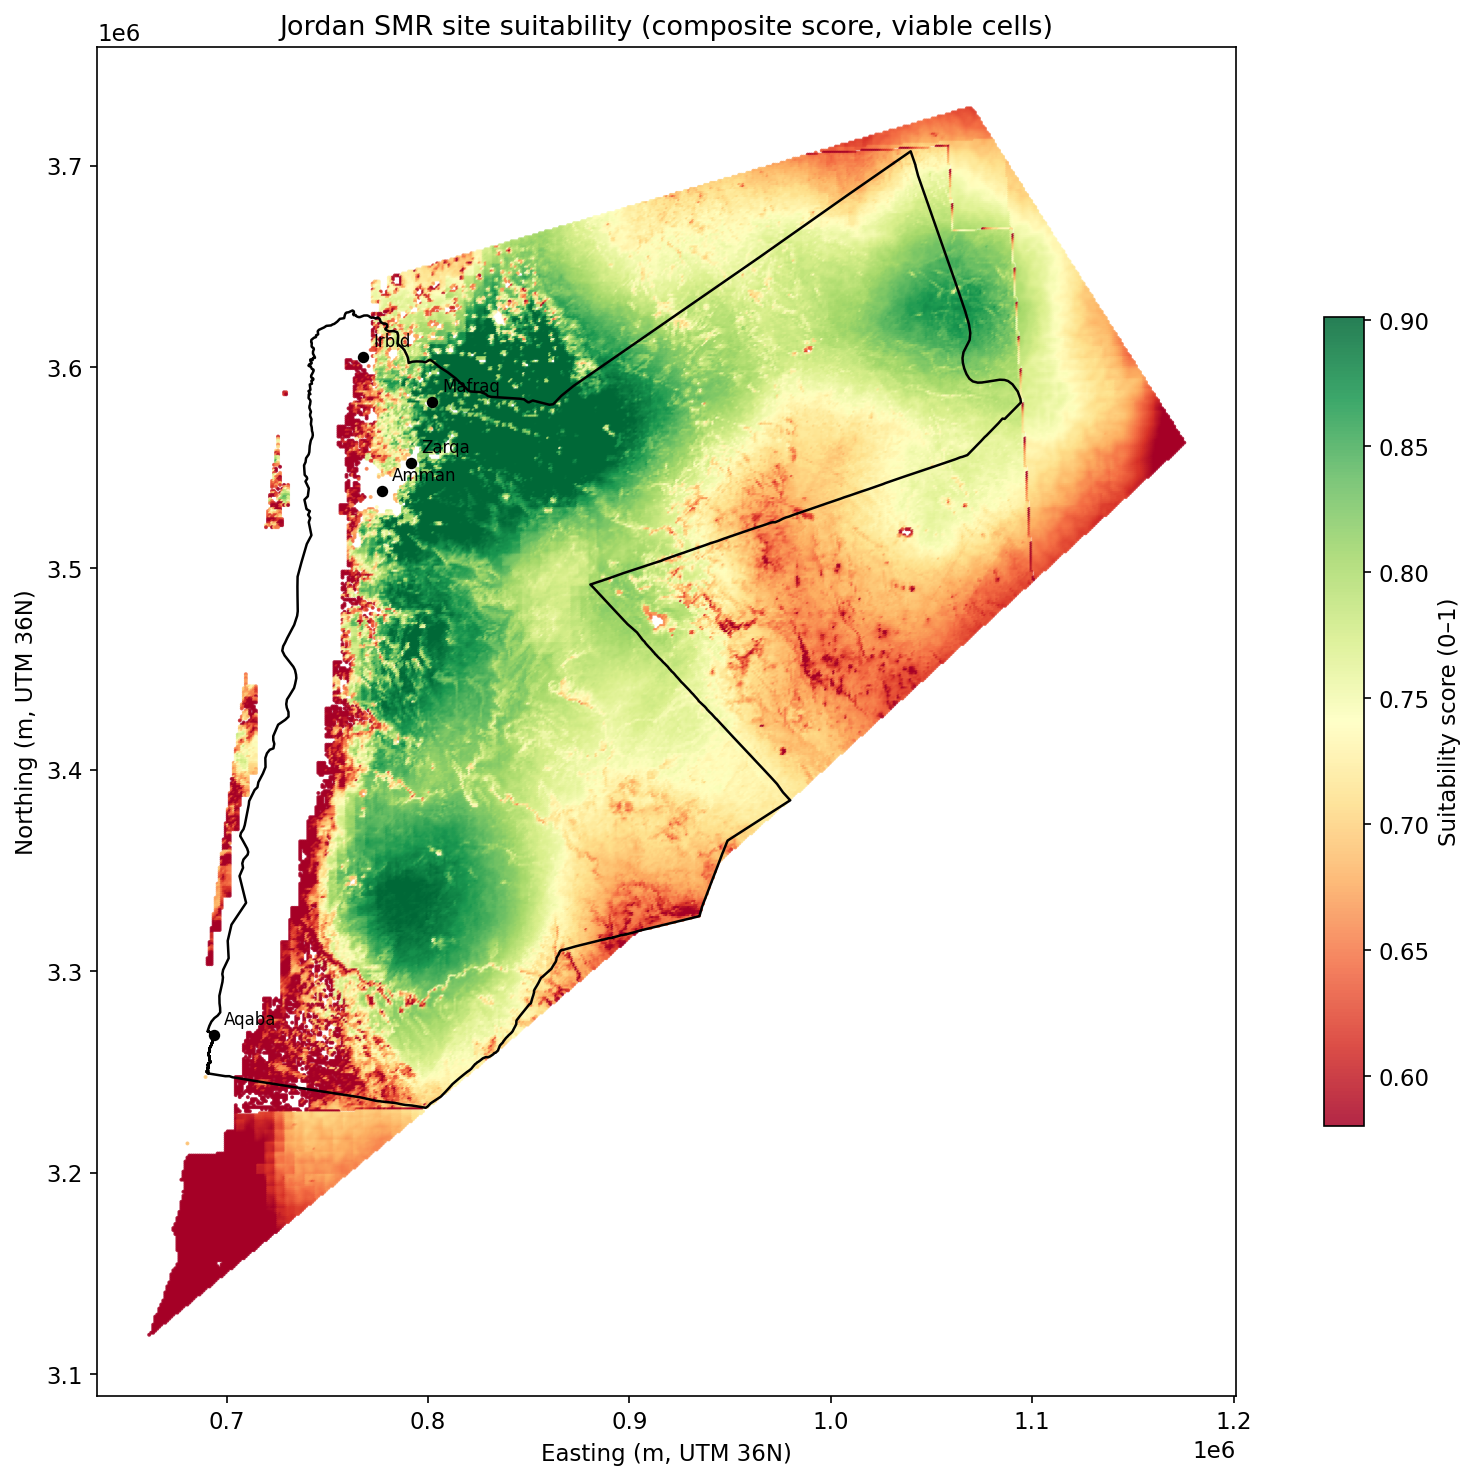

In [31]:
# Section 7 — Suitability heatmap with stretched colormap + context

# Viable cells with suitability scores
viable_sc = df_ml[df_ml['suitability_score'].notna()].copy()

# Score distribution
s = viable_sc['suitability_score']
print("Suitability score distribution (viable cells):")
print("  min :", float(s.min()))
print("  max :", float(s.max()))
print("  mean:", float(s.mean()))
print("  std :", float(s.std()))
print("  p10 :", float(s.quantile(0.10)))
print("  p90 :", float(s.quantile(0.90)))

vmin = float(s.quantile(0.05))
vmax = float(s.quantile(0.95))
print("Using vmin =", vmin, "vmax =", vmax, "for colormap stretch")

fig, ax = plt.subplots(figsize=(12, 10))
sc = ax.scatter(
    viable_sc['x_utm'], viable_sc['y_utm'],
    c=viable_sc['suitability_score'],
    cmap='RdYlGn',  # red = low, green = high
    vmin=vmin, vmax=vmax,
    s=0.8, alpha=0.85, rasterized=True,
)

# Jordan boundary (UTM)
transformer = Transformer.from_crs('EPSG:4326', 'EPSG:32636', always_xy=True)
jordan_utm.boundary.plot(ax=ax, color='black', linewidth=1.2, zorder=4)

# Major Jordanian cities
cities = {
    'Amman':  (35.93, 31.95),
    'Zarqa':  (36.09, 32.07),
    'Irbid':  (35.85, 32.55),
    'Aqaba':  (35.00, 29.53),
    'Mafraq': (36.21, 32.34),
}

for name, (lon, lat) in cities.items():
    x, y = transformer.transform(lon, lat)
    ax.scatter(x, y, c='black', s=20, zorder=5)
    ax.text(x + 5000, y + 5000, name, color='black', fontsize=8, zorder=6)

cb = plt.colorbar(sc, ax=ax, shrink=0.6)
cb.set_label('Suitability score (0–1)')
ax.set_xlabel('Easting (m, UTM 36N)')
ax.set_ylabel('Northing (m, UTM 36N)')
ax.set_title('Jordan SMR site suitability (composite score, viable cells)')
ax.set_aspect('equal')

plt.tight_layout()
# Paper figure (300 DPI) + keep original filename for backwards-compatibility
plt.savefig(OUTPUT_DIR / 'fig5_suitability_map.png', dpi=300, bbox_inches='tight')
plt.savefig(OUTPUT_DIR / 'jordan_suitability_map.png', dpi=300, bbox_inches='tight')
plt.show()


# Section 7 — Suitability heatmap with stretched colormap + context

# Viable cells with suitability scores
viable_sc = df_ml[df_ml['suitability_score'].notna()].copy()

# Score distribution
s = viable_sc['suitability_score']
print("Suitability score distribution (viable cells):")
print("  min :", float(s.min()))
print("  max :", float(s.max()))
print("  mean:", float(s.mean()))
print("  std :", float(s.std()))
print("  p10 :", float(s.quantile(0.10)))
print("  p90 :", float(s.quantile(0.90)))

vmin = float(s.quantile(0.05))
vmax = float(s.quantile(0.95))
print("Using vmin =", vmin, "vmax =", vmax, "for colormap stretch")

fig, ax = plt.subplots(figsize=(12, 10))
sc = ax.scatter(
    viable_sc['x_utm'], viable_sc['y_utm'],
    c=viable_sc['suitability_score'],
    cmap='RdYlGn',  # red = low, green = high
    vmin=vmin, vmax=vmax,
    s=0.8, alpha=0.85, rasterized=True,
)

# Approximate Jordan border outline (same polygon as data-prep fallback)
transformer = Transformer.from_crs('EPSG:4326', 'EPSG:32636', always_xy=True)

jordan_coords_lonlat = [
    (35.005, 29.500), (35.005, 29.185), (35.720, 29.185),
    (36.750, 29.185), (37.680, 29.185), (39.005, 29.185),
    (39.305, 29.500), (39.305, 30.500), (39.100, 31.700),
    (38.570, 33.375), (37.980, 33.375), (37.000, 33.380),
    (36.600, 33.380), (36.390, 32.970), (35.550, 32.550),
    (35.550, 31.800), (35.020, 31.300), (35.005, 29.500),
]

jx, jy = zip(*[transformer.transform(lon, lat) for lon, lat in jordan_coords_lonlat])
ax.plot(jx, jy, color='black', linewidth=0.8, alpha=0.9)

# Major Jordanian cities
cities = {
    'Amman':  (35.93, 31.95),
    'Zarqa':  (36.09, 32.07),
    'Irbid':  (35.85, 32.55),
    'Aqaba':  (35.00, 29.53),
    'Mafraq': (36.21, 32.34),
}

for name, (lon, lat) in cities.items():
    x, y = transformer.transform(lon, lat)
    ax.scatter(x, y, c='black', s=20, zorder=5)
    ax.text(x + 5000, y + 5000, name, color='black', fontsize=8, zorder=6)

cb = plt.colorbar(sc, ax=ax, shrink=0.6)
cb.set_label('Suitability score (0–1)')
ax.set_xlabel('Easting (m, UTM 36N)')
ax.set_ylabel('Northing (m, UTM 36N)')
ax.set_title('Jordan SMR site suitability (composite score, viable cells)')
ax.set_aspect('equal')

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'jordan_suitability_map.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close(fig)

In [ ]:
top20 = df_ml.nlargest(20, 'suitability_score')
cols_out = ['cell_id', 'lon', 'lat', 'x_utm', 'y_utm', 'suitability_score', 'stage1_label', 'stage1_prob'] + use_cols
cols_out = [c for c in cols_out if c in top20.columns]
top20_export = top20[cols_out].copy()
top20_export.to_csv(OUTPUT_DIR / 'jordan_top_sites.csv', index=False)

print('Top 20 candidate sites:')
display(top20_export[['cell_id', 'lon', 'lat', 'suitability_score'] + use_cols[:6]])

Top 20 candidate sites:


,cell_id,lon,lat,suitability_score,elevation_m,slope_deg,pga,dist_river_km,dist_lake_km,dist_dead_sea_km
47777,88662,36.165011,32.159442,1.000000,564.175903,1.805253,0.093978,1.004678,0.212672,70.941519
46880,87605,36.197408,32.176658,0.996183,555.707520,2.062670,0.093969,0.878831,3.216606,74.516742
46434,87078,36.229498,32.184857,0.988082,581.429932,2.117467,0.093938,0.549935,6.176607,77.447552
46430,87074,36.187131,32.185933,0.986180,555.230713,2.464657,0.093978,0.544250,3.159302,74.430112
46432,87076,36.208315,32.185397,0.982181,570.088318,2.609269,0.093938,0.749442,4.609665,75.927482
38930,78074,36.298583,32.336327,0.981770,662.913696,1.609011,0.102630,0.835795,22.852296,93.422235
46431,87075,36.197723,32.185665,0.980088,563.643066,2.596478,0.093967,0.574125,3.854852,75.175874
46433,87077,36.218906,32.185127,0.979670,579.528870,2.605374,0.093938,1.028994,5.395747,76.684763
46881,87606,36.207999,32.176389,0.979570,569.680908,2.738818,0.093938,1.274424,3.984397,75.274932
46879,87604,36.186817,32.176925,0.979251,549.222107,2.962999,0.093978,0.133319,2.440783,73.764316


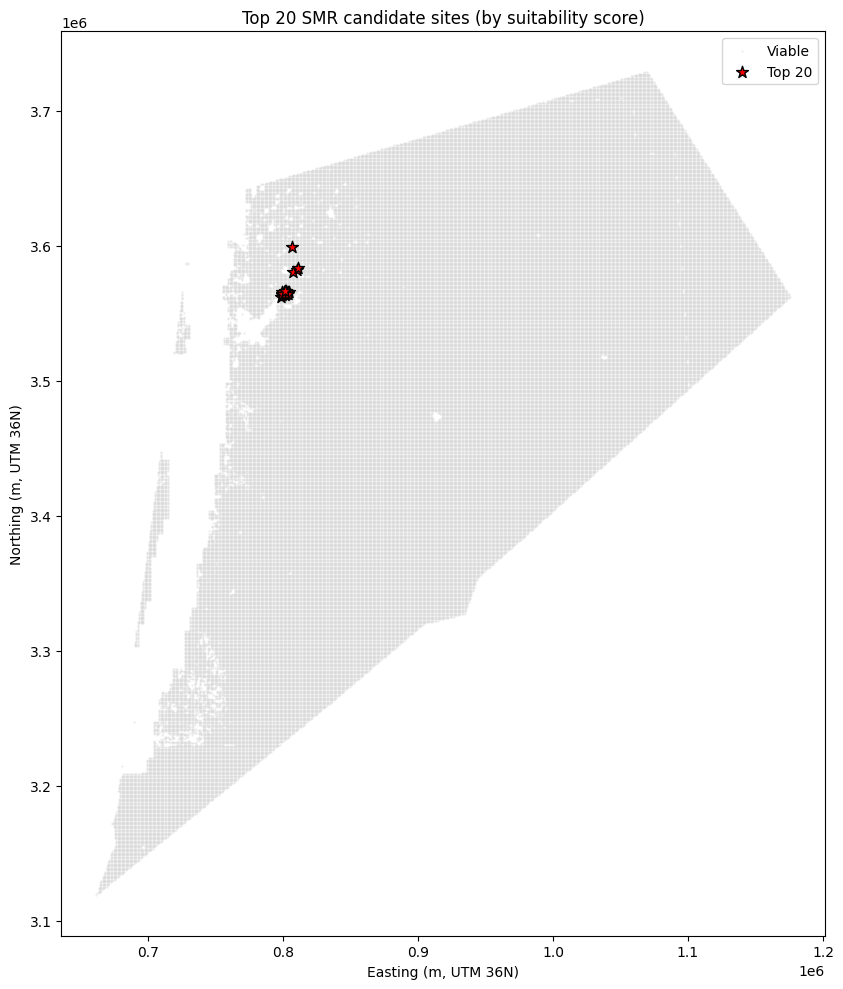

In [ ]:
# Plot top 20 on Jordan map
fig, ax = plt.subplots(figsize=(10, 10))
ax.scatter(df_ml['x_utm'], df_ml['y_utm'], c='lightgray', s=0.2, alpha=0.5, label='Viable', rasterized=True)
ax.scatter(top20['x_utm'], top20['y_utm'], c='red', s=80, marker='*', edgecolors='black', label='Top 20', zorder=5)
ax.set_xlabel('Easting (m, UTM 36N)')
ax.set_ylabel('Northing (m, UTM 36N)')
ax.set_title('Top 20 SMR candidate sites (by suitability score)')

# Jordan boundary (UTM)
jordan_utm.boundary.plot(ax=ax, color='black', linewidth=1.2, zorder=4)

ax.legend()
ax.set_aspect('equal')
plt.tight_layout()

# Paper figure (300 DPI) + keep original filename for backwards-compatibility
plt.savefig(OUTPUT_DIR / 'fig6_top20_map.png', dpi=300, bbox_inches='tight')
plt.savefig(OUTPUT_DIR / 'jordan_top20_map.png', dpi=300, bbox_inches='tight')
plt.show()

# Plot top 20 on Jordan map
fig, ax = plt.subplots(figsize=(10, 10))
ax.scatter(df_ml['x_utm'], df_ml['y_utm'], c='lightgray', s=0.2, alpha=0.5, label='Viable', rasterized=True)
ax.scatter(top20['x_utm'], top20['y_utm'], c='red', s=80, marker='*', edgecolors='black', label='Top 20', zorder=5)
ax.set_xlabel('Easting (m, UTM 36N)')
ax.set_ylabel('Northing (m, UTM 36N)')
ax.set_title('Top 20 SMR candidate sites (by suitability score)')
ax.legend()
ax.set_aspect('equal')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'jordan_top20_map.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close(fig)

In [33]:
# Left join ML columns from df_ml onto base features df (restart-safe)

ml_cols = ['stage1_label', 'stage1_prob', 'suitability_score', 'suitability_target', 'label_positive']

# Load base features table if needed (so this cell can't be broken by a different global `df`)
required_base = {'cell_id', 'viable', 'lon', 'lat'}
if 'df' in globals() and required_base.issubset(set(df.columns)):
    df_base = df
else:
    features_csv = (features_path if 'features_path' in globals() else (OUTPUT_DIR / 'jordan_smr_features.csv'))
    df_base = pd.read_csv(features_csv)

# Load ML table if needed
if 'df_ml' not in globals() or 'cell_id' not in df_ml.columns:
    features_final_csv = (features_final_path if 'features_final_path' in globals() else (OUTPUT_DIR / 'jordan_smr_features_final.csv'))
    df_ml = pd.read_csv(features_final_csv)

# Build merge frame with only available ML cols
ml_cols_present = [c for c in ml_cols if c in df_ml.columns]
merge_df = df_ml[['cell_id'] + ml_cols_present].copy()

df_final = df_base.merge(merge_df, on='cell_id', how='left')

df_final.to_csv(OUTPUT_DIR / 'jordan_smr_features_final.csv', index=False)

n_total = len(df_final)
n_viable = (df_final['viable'] == 1).sum()
n_with_score = df_final['suitability_score'].notna().sum()
top1 = df_final.loc[df_final['suitability_score'].idxmax()] if n_with_score > 0 else None

print('Final summary')
print('  Total cells:        ', n_total)
print('  Viable (hard filter):', n_viable)
print('  With suitability:    ', n_with_score)
if top1 is not None:
    print('  Top site cell_id:    ', int(top1['cell_id']))
    print('  Top site lon, lat:   ', round(top1['lon'], 4), round(top1['lat'], 4))
    print('  Top site score:      ', round(top1['suitability_score'], 4))
print('\nSaved:', OUTPUT_DIR / 'jordan_smr_features_final.csv')

Final summary
  Total cells:         151156
  Viable (hard filter): 133166
  With suitability:     133166
  Top site cell_id:     88662
  Top site lon, lat:    36.165 32.1594
  Top site score:       1.0

Saved: /Users/rajinasrallah/Desktop/databases/output/final/jordan_smr_features_final.csv


In [ ]:
# Top sites
top = pd.read_csv('output/final/jordan_top_sites.csv')
print(top[['cell_id','lon','lat','suitability_score','pga','dist_river_km','dist_dead_sea_km','population_density']].head(10).to_string())

   cell_id        lon        lat  suitability_score       pga  dist_river_km  dist_dead_sea_km  population_density
0    88662  36.165011  32.159442           1.000000  0.093978       1.004678         70.941519           23.166224
1    87605  36.197408  32.176658           0.996183  0.093969       0.878831         74.516742            1.732704
2    87078  36.229498  32.184857           0.988082  0.093938       0.549935         77.447552            0.219758
3    87074  36.187131  32.185933           0.986180  0.093978       0.544250         74.430112           10.211090
4    87076  36.208315  32.185397           0.982181  0.093938       0.749442         75.927482            2.528193
5    78074  36.298583  32.336327           0.981770  0.102630       0.835795         93.422235            7.891645
6    87075  36.197723  32.185665           0.980088  0.093967       0.574125         75.175874           14.691523
7    87077  36.218906  32.185127           0.979670  0.093938       1.028994    

In [34]:
# Top sites
top = pd.read_csv(OUTPUT_DIR / 'jordan_top_sites.csv')
print(top[['cell_id','lon','lat','suitability_score','pga','dist_river_km','dist_dead_sea_km','population_density']].head(10).to_string())

   cell_id        lon        lat  suitability_score       pga  dist_river_km  dist_dead_sea_km  population_density
0    88662  36.165011  32.159442           1.000000  0.093978       1.004678         70.941519           23.166224
1    87605  36.197408  32.176658           0.996183  0.093969       0.878831         74.516742            1.732704
2    87078  36.229498  32.184857           0.988082  0.093938       0.549935         77.447552            0.219758
3    87074  36.187131  32.185933           0.986180  0.093978       0.544250         74.430112           10.211090
4    87076  36.208315  32.185397           0.982181  0.093938       0.749442         75.927482            2.528193
5    78074  36.298583  32.336327           0.981770  0.102630       0.835795         93.422235            7.891645
6    87075  36.197723  32.185665           0.980088  0.093967       0.574125         75.175874           14.691523
7    87077  36.218906  32.185127           0.979670  0.093938       1.028994    